# 18. KAMP 보강 — 결합 사양 추천, KAMP 안에서 가능한 검증, 검사 계획
결합 사양 = raw PVC(제공 4개 + 파생 3개, 일별 개수로 학습, 10시드 평균)와 D4 규칙(파생 5종 날짜 안 이탈 크기 합, 학습 없음)의 **날짜 안 순위 평균**.
Stellantis N.V.에서 5% 예산 18.5개(raw 8.0)로 저예산에서 보완 효과가 있었다(17, 탐색 결과). KAMP에는 타점 정답이 없으므로 아래만 할 수 있다.
(a) 결합 추천 목록 (b) 날짜 단위 검증: 날짜 하나 빼고 학습한 추정 개수와 실제 개수, 전역 기준선을 넘는 타점 비율과 실제 일별 불량률의 관계
(c) 방법 간 추천 겹침 (d) 날짜별 검사 계획표 (e) 추천 타점의 조건 요약

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy.stats import spearmanr
import br
from br import spec as S, plot as P
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
fin = pd.read_csv(br.RES / "final_kamp_recommendations.csv")
d4 = pd.read_csv(br.RES / "kamp_d4_rule_scores.csv")
pl = pd.read_csv(br.RES / "kamp_pseudo_labels.csv")
_, kday, kcnt, _, kblk = S.load_kamp()
raw = pd.read_excel(wldata.KAMP_XLSX, sheet_name="Raw data")
ok = ~kblk
lab_days = [d for d in kcnt.index if not np.isnan(kcnt[d])]
def day_pct(s):
    out = np.full(len(s), np.nan); out[ok] = pd.Series(s[ok]).groupby(kday[ok]).rank(pct=True).values; return out
R_raw, R_d4 = day_pct(fin["위험점수"].values), day_pct(d4["D4 이탈크기합"].values)
R_comb = (R_raw + R_d4) / 2
sc = pd.read_pickle(br.RES / "same_model_scores.pkl")
ae = np.mean([g.sort_values("row").score.values for _, g in sc[(sc.data == "kamp") & (sc.model == "AE (정답 미사용)")].groupby("seed")], 0)
R_ae = day_pct(ae)

## (a) 결합 사양 추천 목록

In [2]:
def top_mask(R, frac):
    m = np.zeros(len(R), bool)
    for d in np.unique(kday):
        mm = ok & (kday == d); k = int(np.ceil(frac * mm.sum())); ix = np.flatnonzero(mm)
        m[ix[np.argsort(-R[mm], kind="stable")[:k]]] = True
    return m
out = pd.DataFrame({"idx": raw["idx"], "date": kday, "상태": np.where(kblk, "품질확인(복사 블록)", "순위 부여"),
                    "raw위험점수_순위백분위": R_raw, "D4이탈크기_순위백분위": R_d4, "결합점수": R_comb})
out["일내순위(결합)"] = np.nan
out.loc[ok, "일내순위(결합)"] = pd.Series(-R_comb[ok]).groupby(kday[ok]).rank(method="first").values
for f in (.05, .1, .2):
    out[f"추천_{int(f*100)}%"] = top_mask(R_comb, f)
out["의사라벨 등급"] = pl["검사등급"].values
out = pd.concat([out, raw[["weld current(kA)", "weld Voltage(v)", "weld time(ms)", "weld force(bar)"]]], axis=1)
out.to_csv(br.RES / "final_kamp_recommendations_combined.csv", index=False, encoding="utf-8-sig")
print("저장: final_kamp_recommendations_combined.csv", out.shape)

저장: final_kamp_recommendations_combined.csv (11939, 15)


## (b) KAMP 안에서 할 수 있는 날짜 단위 검증
타점 정답은 없지만 **날짜별 불량 수는 있다.** 위험 점수가 의미가 있다면 위험한 타점이 많은 날에 불량도 많아야 한다.
날짜마다 "전체 기간 공통 기준선(상위 10% 경계) 을 넘는 타점 비율"을 구하고, 실제 일별 불량률과 순위 상관을 본다(8일, 순열 p).
raw PVC 점수는 날짜 하나 빼고 학습한 값이라 그 날의 개수를 보지 않았다. D4·AE는 정답을 쓰지 않는다.
날짜 8개라 검정력이 매우 낮다는 점을 전제로 읽는다.

In [3]:
rate = pd.Series({d: kcnt[d] / (kday == d).sum() for d in lab_days})
rng = np.random.default_rng(9)
def day_check(score, name):
    s = np.where(ok, score, np.nan); thr = np.nanquantile(s, .9)
    share = pd.Series({d: np.nanmean(s[kday == d] > thr) for d in lab_days})
    rho = spearmanr(share, rate).statistic
    null = [spearmanr(share, rng.permutation(rate.values)).statistic for _ in range(5000)]
    return {"방법": name, "날짜별 고위험 비율 범위": f"{share.min():.3f}~{share.max():.3f}", "일별 불량률과 순위상관": round(rho, 3),
            "순열 p(단측, 양의 관계)": round((np.sum(np.array(null) >= rho) + 1) / 5001, 3)}
raw_abs = fin["위험점수"].values; d4_abs = d4["D4 이탈크기합"].values
rows = [day_check(raw_abs, "raw PVC (날짜 하나 빼고 학습)"), day_check(d4_abs, "D4 이탈 크기 규칙"), day_check(ae, "AE (정답 미사용)")]
pc = pd.read_pickle(br.RES / "same_model_scores.pkl")
for m in ["PVC MLP", "집계 로지스틱", "고정 불량률"]:
    p_ = np.mean([g.sort_values("row").prob.values for _, g in pc[(pc.data == "kamp") & (pc.model == m)].groupby("seed")], 0)
    est = pd.Series({d: np.nansum(p_[kday == d]) / (kday == d).sum() for d in lab_days})
    rho = spearmanr(est, rate).statistic
    null = [spearmanr(est, rng.permutation(rate.values)).statistic for _ in range(5000)]
    rows.append({"방법": f"{m} 추정 불량률", "날짜별 고위험 비율 범위": "-", "일별 불량률과 순위상관": round(rho, 3) if rho == rho else np.nan,
                 "순열 p(단측, 양의 관계)": round((np.sum(np.array(null) >= rho) + 1) / 5001, 3) if rho == rho else np.nan})
chk = pd.DataFrame(rows); chk.to_csv(br.RES / "kamp_day_level_check.csv", index=False, encoding="utf-8-sig"); display(chk)
display(pd.DataFrame({"타점": [(kday == d).sum() for d in lab_days], "불량": [kcnt[d] for d in lab_days], "불량률(%)": (rate * 100).round(2).values}, index=lab_days))

,방법,날짜별 고위험 비율 범위,일별 불량률과 순위상관,"순열 p(단측, 양의 관계)"
0,raw PVC (날짜 하나 빼고 학습),0.037~0.217,-0.024,0.523
1,D4 이탈 크기 규칙,0.019~0.169,-0.286,0.776
2,AE (정답 미사용),0.057~0.179,0.238,0.293
3,PVC MLP 추정 불량률,-,0.214,0.305
4,집계 로지스틱 추정 불량률,-,0.452,0.135
5,고정 불량률 추정 불량률,-,-0.976,1.000


,타점,불량,불량률(%)
2020-03-24,1200,4.0,0.33
2020-03-25,1352,8.0,0.59
2020-03-26,1000,7.0,0.70
2020-03-30,1470,4.0,0.27
2020-03-31,1800,5.0,0.28
2020-04-02,2000,4.0,0.20
2020-04-03,800,4.0,0.50
2020-04-07,669,3.0,0.45


## (c) 방법 간 상위 10% 추천 겹침 (8+1일 평균, 복사 블록 제외)

In [4]:
M = {"raw PVC": top_mask(R_raw, .1), "D4 규칙": top_mask(R_d4, .1), "결합": top_mask(R_comb, .1), "AE": top_mask(R_ae, .1)}
M["의사라벨 A+B"] = np.isin(pl["검사등급"].values, ["A", "B"])
names = list(M)
ov = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        ov.loc[a, b] = (M[a] & M[b]).sum() / M[a].sum()
print("행 방법이 고른 타점 중 열 방법도 고른 비율"); display(ov.round(2))

행 방법이 고른 타점 중 열 방법도 고른 비율


,raw PVC,D4 규칙,결합,AE,의사라벨 A+B
raw PVC,1.00,0.20,0.48,0.05,0.21
D4 규칙,0.20,1.00,0.44,0.23,0.04
결합,0.48,0.44,1.00,0.11,0.11
AE,0.05,0.23,0.11,1.00,0.03
의사라벨 A+B,1.00,0.21,0.55,0.13,1.00


## (d) 날짜별 검사 계획표 (결합 사양)

In [5]:
p_agg = np.mean([g.sort_values("row").prob.values for _, g in pc[(pc.data == "kamp") & (pc.model == "집계 로지스틱")].groupby("seed")], 0)
fin_est = fin.groupby("date")["추정불량수"].first()
plan = pd.DataFrame({"전체 타점": pd.Series(kday).value_counts().sort_index(),
                     "품질확인(복사 블록)": pd.Series(kblk).groupby(kday).sum(),
                     "순위 대상": pd.Series(ok).groupby(kday).sum()})
for f in (.05, .1, .2):
    plan[f"검사 {int(f*100)}%"] = out.groupby("date")[f"추천_{int(f*100)}%"].sum()
plan["의사라벨 A"] = (out["의사라벨 등급"] == "A").groupby(kday).sum()
plan["추정 불량 수"] = fin_est.round(1)
plan["실제 불량 수"] = kcnt.reindex(plan.index)
plan.loc["합계"] = plan.sum(numeric_only=True)
plan.to_csv(br.RES / "kamp_daily_inspection_plan.csv", encoding="utf-8-sig"); display(plan)

,전체 타점,품질확인(복사 블록),순위 대상,검사 5%,검사 10%,검사 20%,의사라벨 A,추정 불량 수,실제 불량 수
2020-03-24,1200.0,0.0,1200.0,60.0,120.0,240.0,4.0,3.4,4.0
2020-03-25,1352.0,291.0,1061.0,54.0,107.0,213.0,8.0,5.2,8.0
2020-03-26,1000.0,0.0,1000.0,50.0,100.0,200.0,7.0,4.0,7.0
2020-03-27,1648.0,291.0,1357.0,68.0,136.0,272.0,6.0,5.7,NaN
2020-03-30,1470.0,0.0,1470.0,74.0,147.0,294.0,4.0,6.1,4.0
2020-03-31,1800.0,291.0,1509.0,76.0,151.0,302.0,5.0,6.5,5.0
2020-04-02,2000.0,0.0,2000.0,100.0,200.0,400.0,4.0,5.4,4.0
2020-04-03,800.0,291.0,509.0,26.0,51.0,102.0,4.0,5.1,4.0
2020-04-07,669.0,0.0,669.0,34.0,67.0,134.0,3.0,4.0,3.0
합계,11939.0,1164.0,10775.0,542.0,1079.0,2157.0,45.0,45.4,39.0


## (e) 추천 타점의 조건 요약 (결합 10%, 블록 제외, 설명용)

In [6]:
cols = {"weld current(kA)": "전류(kA)", "weld Voltage(v)": "전압(V)", "weld time(ms)": "통전시간(ms)", "weld force(bar)": "가압력(bar)"}
top10 = out["추천_10%"].values; rest = ok & ~top10
summ = pd.DataFrame({"추천 10% 평균": out.loc[top10, list(cols)].mean(), "나머지 평균": out.loc[rest, list(cols)].mean(),
                     "추천 10% 표준편차": out.loc[top10, list(cols)].std(), "나머지 표준편차": out.loc[rest, list(cols)].std()}).rename(index=cols)
display(summ.round(3))
med = out.loc[ok, list(cols)].median()
cond = {"전류가 중앙값보다 0.1kA 이상 낮음": out["weld current(kA)"] < med["weld current(kA)"] - 0.1,
        "통전시간 71ms 이하": out["weld time(ms)"] <= 71,
        "가압력 2.385bar 초과": out["weld force(bar)"] > 2.385,
        "전압이 중앙값에서 0.01V 이상 벗어남": (out["weld Voltage(v)"] - med["weld Voltage(v)"]).abs() >= 0.01}
cs = pd.DataFrame({"추천 10% 중 비율": {k: v[top10].mean() for k, v in cond.items()},
                   "나머지 중 비율": {k: v[rest].mean() for k, v in cond.items()}})
cs["배수"] = cs["추천 10% 중 비율"] / cs["나머지 중 비율"]
cs.to_csv(br.RES / "kamp_recommended_conditions.csv", encoding="utf-8-sig"); display(cs.round(3))

,추천 10% 평균,나머지 평균,추천 10% 표준편차,나머지 표준편차
전류(kA),14.598,14.708,0.058,0.085
전압(V),2.704,2.702,0.008,0.009
통전시간(ms),71.531,71.747,0.655,0.626
가압력(bar),2.368,2.335,0.051,0.053


,추천 10% 중 비율,나머지 중 비율,배수
전류가 중앙값보다 0.1kA 이상 낮음,0.831,0.236,3.529
통전시간 71ms 이하,0.464,0.319,1.454
가압력 2.385bar 초과,0.105,0.061,1.730
전압이 중앙값에서 0.01V 이상 벗어남,0.038,0.025,1.529


## 그림 — KAMP 보강 요약

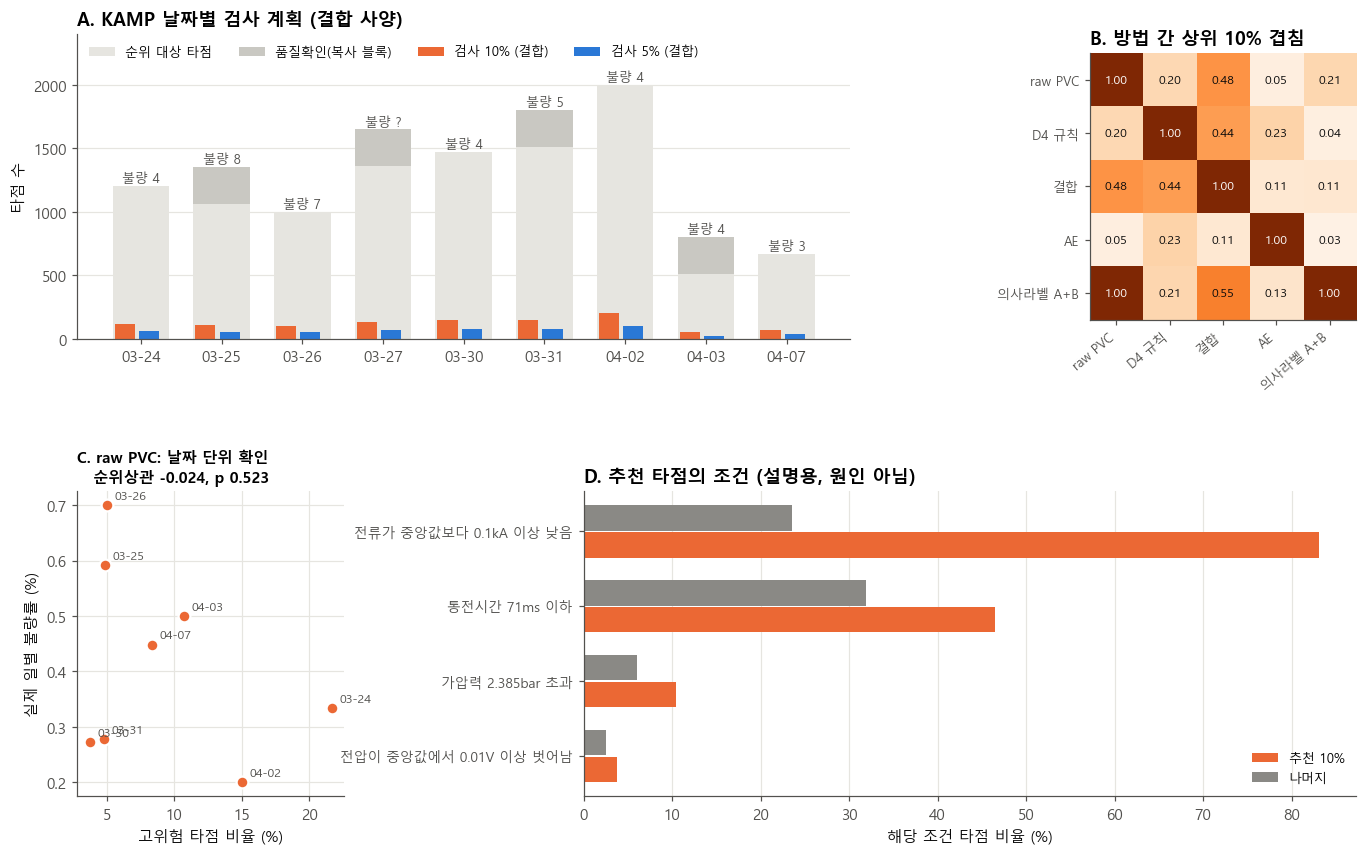

In [7]:
fig = plt.figure(figsize=(15, 9)); gs = fig.add_gridspec(2, 3, hspace=.5, wspace=.9)
ax = fig.add_subplot(gs[0, :2])
pl_ = plan.drop("합계"); x = np.arange(len(pl_))
ax.bar(x, pl_["순위 대상"], .7, color=P.GRID, label="순위 대상 타점")
ax.bar(x, pl_["품질확인(복사 블록)"], .7, bottom=pl_["순위 대상"], color="#c9c8c2", label="품질확인(복사 블록)")
ax.bar(x - .2, pl_["검사 10%"], .25, color=P.PAL[1], label="검사 10% (결합)")
ax.bar(x + .1, pl_["검사 5%"], .25, color=P.PAL[0], label="검사 5% (결합)")
for i, (d, r) in enumerate(pl_.iterrows()):
    a = "?" if np.isnan(r["실제 불량 수"]) else int(r["실제 불량 수"])
    ax.text(i, r["전체 타점"] + 30, f"불량 {a}", ha="center", fontsize=8.5, color=P.INK2)
ax.set_xticks(x); ax.set_xticklabels([d[5:] for d in pl_.index]); ax.set_ylabel("타점 수"); ax.grid(axis="x", visible=False)
ax.set_title("A. KAMP 날짜별 검사 계획 (결합 사양)", loc="left", fontweight="bold"); ax.legend(fontsize=8.5, ncol=4, loc="upper left"); ax.set_ylim(0, 2400)
ax = fig.add_subplot(gs[0, 2])
im = ax.imshow(ov.values.astype(float), cmap="Oranges", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8.5); ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8.5)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{ov.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if ov.values[i, j] > .6 else P.INK)
ax.grid(False); ax.set_title("B. 방법 간 상위 10% 겹침", loc="left", fontweight="bold")
ax = fig.add_subplot(gs[1, 0])
s = np.where(ok, raw_abs, np.nan); thr = np.nanquantile(s, .9)
share = pd.Series({d: np.nanmean(s[kday == d] > thr) for d in lab_days})
ax.scatter(share * 100, rate * 100, s=60, color=P.PAL[1], edgecolor="white", linewidth=1.5, zorder=3)
for d in lab_days: ax.annotate(d[5:], (share[d] * 100, rate[d] * 100), textcoords="offset points", xytext=(5, 4), fontsize=8, color=P.INK2)
r_ = chk.iloc[0]
ax.set_xlabel("고위험 타점 비율 (%)"); ax.set_ylabel("실제 일별 불량률 (%)")
ax.set_title(f"C. raw PVC: 날짜 단위 확인\n   순위상관 {r_['일별 불량률과 순위상관']}, p {r_['순열 p(단측, 양의 관계)']}", loc="left", fontweight="bold", fontsize=10)
ax = fig.add_subplot(gs[1, 1:])
cs_ = cs.reset_index().rename(columns={"index": "조건"})
y_ = np.arange(len(cs_))
ax.barh(y_ + .18, cs_["추천 10% 중 비율"] * 100, .34, color=P.PAL[1], label="추천 10%")
ax.barh(y_ - .18, cs_["나머지 중 비율"] * 100, .34, color=P.GRAY, label="나머지")
ax.set_yticks(y_); ax.set_yticklabels(cs_["조건"], fontsize=9); ax.invert_yaxis(); ax.set_xlabel("해당 조건 타점 비율 (%)"); ax.grid(axis="y", visible=False)
ax.set_title("D. 추천 타점의 조건 (설명용, 원인 아님)", loc="left", fontweight="bold"); ax.legend(fontsize=8.5)
P.save(fig, "16_kamp_deep"); plt.show()